# Project work 3, Mattia Franchi

In this notebook, I continue my work from parts 1 and 2. I download the shapefiles of the price areas and of the NVE regions from atlas.nve.no, sample 1000 random locations in each area with GeoPandas and store them in MongoDB. I write a function that downloads hourly ERA5 weather data from open-meteo for an area and a time interval, and I use it for NO3 in 2024. On these data I look for outliers in the precipitation with a DCT high-pass filter and SPC boundaries, and for anomalies in the temperature with the Local Outlier Factor. Finally, I analyse the weekly filling rate of the reservoirs from the NVE API with an STL decomposition and a spectrogram. The same analyses are available in my Streamlit app, on two new pages.

## Useful Links
- GitHub: https://github.com/m4tti4fr4nchi/ind320-m4tti4fr4nchi
- Streamlit: https://ind320-m4tti4fr4nchi-ybf3fy4znakvdenhn4kked.streamlit.app/
- Video: https://youtu.be/0HH0zB0BtxA (I wasn't be able to use panopto, i will try to sold the problem as the 4th part request the pic in pic over the screencast)

## Use of AI
In this third part of the project I used AI more as much as in the second part, mainly Claude. The AI acted as a step-by-step programming assistant: it proposed code whether i wasn't able to manage it myself and configurations, while I ran every step on my own machine, checked the outputs, reported errors back and made the decisions on how to proceed. 
I read every piece of generated code and connected it to the theory covered in class; whenever a code/part was unclear, I asked the AI to explain in depth what was the explanations of the professor's topics.
It also helped with the English of the markdown text, which I edited. I checked that the results in the app match the notebook.

## Log

Part 3 builds on the app and notebook from Part 2, adding geographic data, weather data and time series analysis.

I read the shapefiles from atlas.nve.no with GeoPandas, as shown in the lectures. When reading them, I encountered a decoding issue with the special character "RØ," which I successfully resolved by explicitly setting encoding="utf-8". The regions were then merged into the three main VASS areas, and 1,000 random points were sampled in each of the eight areas and stored in the MongoDB database.

For the weather data, I integrated the open-meteo API, taking advantage of its ability to query multiple geographic points in a single request. To stay within the API's strict rate limits, I made the design choice to download only 10 of the 1,000 sampled points of an area (a parameter of the function) and use their average. During testing, I triggered a 429 "Too Many Requests" error; instead of letting the application crash, I managed this exception directly within the Streamlit app by displaying a clear warning message to the user.

When analyzing outliers and anomalies, I had to make a specific methodological choice because the task text is ambiguous: it asks for the precipitation but calls the filtered signal “temperature variations”. I applied SPC to the precipitation as written and LOF to the temperature, and tested each function on the other variable. Using Statistical Process Control (SPC), With SPC, I detected a 7.6% outlier rate” e “This makes sense, as rainfall has a highly asymmetric distribution with sudden spikes, unlike the more stable shifts in temperature.

The time series analysis was further deepened using STL decomposition and spectrograms. These tools made it possible to clearly visualize the standard annual cycle, pinpoint historically dry years, and observe the dominant 1-cycle-per-year frequency band, giving a concrete physical meaning to the analyzed parameters.

On the front end, the Streamlit app was significantly upgraded. I added a global area selector and implemented a hidden, cached weather download mechanism to ensure the dashboard remained fast and responsive. Two new pages with tabbed layouts were added, and the menu was reorganized into sections for smoother navigation.

Reflecting on the development process and the feedback received from the tutor and peer reviews, I completely overhauled the README file to ensure it was fully detailed, and I chose to submit a PDF report instead of an HTML file. I also ensured that the Streamlit app link remained identical across all project parts. Version control was managed smoothly by doing all active work on a beta branch and merging it into main only after the peer review and the teacher feedback of Part 2 were completed. The most useful aspect of this phase was learning how to merge geospatial data with time series analysis. If I were to do it differently in the future, I would implement API rate-limit handling much earlier in the testing phase to prevent temporary blocks during development.

## 1. Regions and random locations
### Navigate to atlas.nve.no to locate and download the shapefiles corresponding to the electricity areas and precipitation areas. Randomly sample 1000 locations in each region.

In [1]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

# Shapefiles downloaded from atlas.nve.no and kept outside Git (No_sync/ is in .gitignore).
# Each shapefile needs its .shp, .shx, .dbf and .prj files in the same folder.
SHAPE_DIR = "../No_sync"
price_areas = gpd.read_file(f"{SHAPE_DIR}/Budområder/Budområder.shp")
# The .dbf of NVE_Region is UTF-8 without a .cpg file, so the encoding is given explicitly (otherwise "RØ" is misread)
nve_regions = gpd.read_file(f"{SHAPE_DIR}/NVE_Region/NVE_Region.shp", encoding="utf-8")

print("Price areas:", price_areas["budomr"].tolist(), "| CRS:", price_areas.crs)
print("NVE regions:", nve_regions["REGION"].tolist(), "| CRS:", nve_regions.crs)

Price areas: ['NO 1', 'NO 2', 'NO 3', 'NO 4', 'NO 5'] | CRS: EPSG:25833
NVE regions: ['RV', 'RM', 'RN', 'RØ', 'RS'] | CRS: EPSG:25833


In [2]:
# Price areas: "NO 1" -> "NO1", the same names used in the Streamlit app
price = price_areas.assign(area=price_areas["budomr"].str.replace(" ", ""))[["area", "geometry"]]
price["area_type"] = "EL"

# Precipitation areas of Magasinstatistikk: East = RS+RØ, West = RV, North = RM+RN (note in the assignment)
REGION_TO_VASS = {"RS": "VASS1", "RØ": "VASS1", "RV": "VASS2", "RM": "VASS3", "RN": "VASS3"}
vass = (nve_regions.assign(area=nve_regions["REGION"].map(REGION_TO_VASS))
        .dissolve(by="area")          # merge the polygons that belong to the same area
        .reset_index()[["area", "geometry"]])
vass["area_type"] = "VASS"

regions = pd.concat([price, vass], ignore_index=True)
regions = gpd.GeoDataFrame(regions, geometry="geometry", crs=price_areas.crs)
regions["area_km2"] = (regions.area / 1e6).round(0)   # CRS EPSG:25833 is in metres
print(regions.drop(columns="geometry"))

    area area_type  area_km2
0    NO1        EL   60529.0
1    NO2        EL   68760.0
2    NO3        EL  104220.0
3    NO4        EL  203250.0
4    NO5        EL   33349.0
5  VASS1      VASS  138366.0
6  VASS2      VASS   75414.0
7  VASS3      VASS  256327.0


In [3]:
N_POINTS = 1000  # random locations per region

# sample_points draws uniformly random points inside each polygon (one MultiPoint per region);
# rng fixes the random seed so the same points are drawn every time
sampled = regions.set_index("area").geometry.sample_points(size=N_POINTS, rng=42)

# One row per point, converted from UTM metres (EPSG:25833) to longitude/latitude (EPSG:4326)
points = (sampled.explode(index_parts=False)
          .to_crs(epsg=4326)
          .reset_index()
          )
points["area_type"] = points["area"].str[:2].map({"NO": "EL", "VA": "VASS"})
points["point_id"] = points.groupby("area").cumcount()
points["longitude"] = points.geometry.x.round(5)
points["latitude"] = points.geometry.y.round(5)
points = points[["area_type", "area", "point_id", "longitude", "latitude"]]
print(points.groupby("area").size())
points.head()

area
NO1      1000
NO2      1000
NO3      1000
NO4      1000
NO5      1000
VASS1    1000
VASS2    1000
VASS3    1000
dtype: int64


,area_type,area,point_id,longitude,latitude
0,EL,NO1,0,9.57227,60.77436
1,EL,NO1,1,11.30651,61.44100
2,EL,NO1,2,8.18261,61.25286
3,EL,NO1,3,11.53145,62.01354
4,EL,NO1,4,10.65694,61.35596


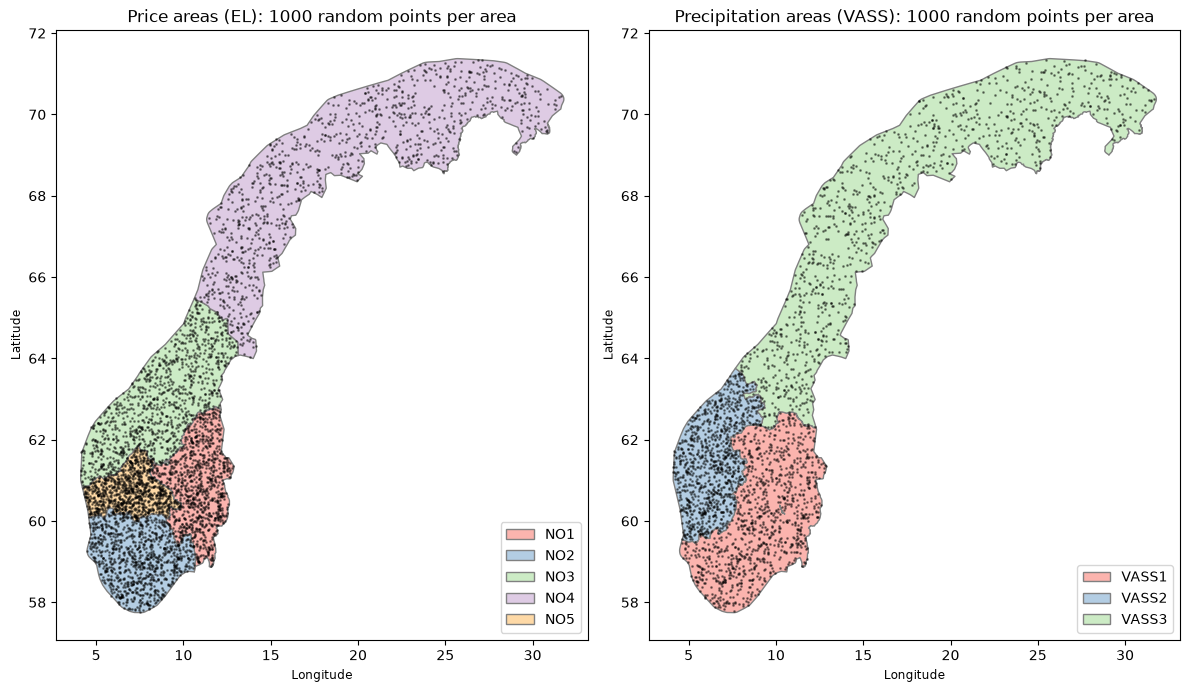

In [4]:
# Map of the areas in longitude/latitude (EPSG:4326), one panel for the price areas and one for the
# precipitation areas, with the sampled points on top to check that they lie inside the right area
regions_wgs84 = regions.to_crs(epsg=4326)
fig, axes = plt.subplots(1, 2, figsize=(12, 7))
for ax, (area_type, title) in zip(axes, [("EL", "Price areas (EL)"), ("VASS", "Precipitation areas (VASS)")]):
    shapes = regions_wgs84[regions_wgs84["area_type"] == area_type]
    shapes.plot(ax=ax, column="area", cmap="Pastel1", edgecolor="grey", legend=True,
                legend_kwds={"loc": "lower right"})
    pts = points[points["area_type"] == area_type]
    ax.scatter(pts["longitude"], pts["latitude"], s=1, color="black", alpha=0.4)
    ax.set_title(f"{title}: {N_POINTS} random points per area")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
plt.tight_layout()
plt.show()

In [5]:
import tomllib
from pymongo import MongoClient

# Connection string from the local secrets file, as in part 2
with open("../.streamlit/secrets.toml", "rb") as f:
    secrets = tomllib.load(f)
mongo_client = MongoClient(secrets["mongo"]["uri"])

# The Streamlit app reads the sampled locations from here, so it needs neither geopandas nor the shapefiles
collection = mongo_client["ind320"]["sample_points"]
collection.delete_many({})  # start from an empty collection, so re-running does not duplicate the points
result = collection.insert_many(points.to_dict("records"))
print(f"{len(result.inserted_ids)} locations stored in MongoDB.")

8000 locations stored in MongoDB.


The price areas come from the "Budområder" shapefile, while the three precipitation areas of Magasinstatistikk are built by merging the NVE regions as described in the assignment (East = RS + RØ, West = RV, North = RM + RN). The map shows that the 1000 points are spread uniformly inside each area, so large areas such as NO4 and VASS3 have a lower density of points. The points are stored in MongoDB, so the Streamlit app can use them without GeoPandas or the shapefiles.

## 2. Weather data from open-meteo
### Create a function that takes a region identifier plus a time interval, looks up the sampled locations and downloads hourly ERA5 data. Apply it to NO3 for 2024.

In [6]:
import requests

ARCHIVE_URL = "https://archive-api.open-meteo.com/v1/archive"

# Hourly ERA5 variables (at most 10, so open-meteo counts one API call per location and 2 weeks)
WEATHER_VARIABLES = ["temperature_2m", "precipitation", "rain", "snowfall", "relative_humidity_2m",
                     "cloud_cover", "wind_speed_10m", "wind_gusts_10m"]


def download_weather(area, start_date, end_date, n_locations=10, variables=WEATHER_VARIABLES, seed=42):
    """Download hourly ERA5 reanalysis data from open-meteo for random sampled locations of one region.

    area: region identifier ("NO1"-"NO5", "VASS1"-"VASS3"); start_date/end_date: "YYYY-MM-DD".
    n_locations of the 1000 sampled points are used: the free API counts every location separately,
    so all 1000 points for a whole year would exceed the daily limit of 10,000 calls.
    Returns one row per hour and location (time in UTC).
    """
    locations = points[points["area"] == area].sample(n=n_locations, random_state=seed)
    days = (pd.Timestamp(end_date) - pd.Timestamp(start_date)).days + 1
    print(f"{area}: {n_locations} location(s), {days} days ≈ {n_locations * days / 14:.0f} API calls")

    params = {
        "latitude": ",".join(locations["latitude"].astype(str)),    # several locations in one request
        "longitude": ",".join(locations["longitude"].astype(str)),
        "start_date": start_date,
        "end_date": end_date,
        "hourly": ",".join(variables),
        "models": "era5",
        "timezone": "UTC",
    }
    response = requests.get(ARCHIVE_URL, params=params, timeout=120)
    response.raise_for_status()
    blocks = response.json()
    if isinstance(blocks, dict):  # one location -> one JSON object, several -> a list
        blocks = [blocks]

    frames = []
    for point_id, block in zip(locations["point_id"], blocks):
        frame = pd.DataFrame(block["hourly"])
        frame["time"] = pd.to_datetime(frame["time"])
        frame["area"] = area
        frame["point_id"] = point_id
        frames.append(frame)
    return pd.concat(frames, ignore_index=True)

In [7]:
# Apply the function to the price area NO3 for the whole year 2024 (10 locations, hourly values)
weather_no3 = download_weather("NO3", "2024-01-01", "2024-12-31")

# Regional average over the downloaded locations: one row per hour
weather_no3_mean = weather_no3.groupby("time")[WEATHER_VARIABLES].mean()
print(weather_no3.shape, "->", weather_no3_mean.shape)
# Overview of the averaged variables: mean, minimum and maximum over the year
weather_no3_mean.describe().round(1).T[["mean", "min", "max"]]

NO3: 10 location(s), 366 days ≈ 261 API calls
(87840, 11) -> (8784, 8)


,mean,min,max
temperature_2m,6.0,-11.5,22.8
precipitation,0.2,0.0,3.1
rain,0.2,0.0,2.4
snowfall,0.0,0.0,1.1
relative_humidity_2m,79.8,40.5,96.9
cloud_cover,78.8,0.5,100.0
wind_speed_10m,13.1,2.5,37.8
wind_gusts_10m,33.0,8.0,104.6


The free open-meteo API allows 600 calls per minute and 10 000 per day, and one year for one location counts as about 26 calls. Downloading all 1000 locations of an area would therefore exceed the daily limit, so the function downloads a random subset of the sampled points (10 by default, a parameter of the function) and the analyses below use their hourly average as the weather of the area.

## 3. Outliers and anomalies
### Average precipitation with DCT high-pass filtering (SATV) and SPC boundaries based on robust statistics
The task asks for the precipitation, but calls the filtered signal "seasonally adjusted temperature variations"; the same task last year used the temperature. The function therefore takes any variable: it is applied to the precipitation as written and tested on the temperature.

In [8]:
import numpy as np
from scipy.fft import dct, idct
from scipy.stats import median_abs_deviation


def spc_outliers(series, cutoff=100, n_std=3):
    """Statistical Process Control on seasonally adjusted variations (SATV) of an hourly series.

    series: pandas Series with a DatetimeIndex (e.g. a regional hourly average).
    cutoff: DCT frequency cut-off; components below it (slow, seasonal variations) are removed.
            With N points, component k has a period of about 2N/k samples (cutoff=100 -> about 1 week of hours).
    n_std: number of robust standard deviations between the median and each SPC boundary.
    Returns the figure, a table of the outliers and a summary.
    """
    values = series.to_numpy()

    # High-pass filter with the Discrete Cosine Transform: remove the slow components and transform back
    coefficients = dct(values, type=1, norm="forward")
    coefficients[:cutoff] = 0
    satv = idct(coefficients, type=1, norm="forward")   # seasonally adjusted variations
    seasonal = values - satv                              # the slow, seasonal part that was removed

    # Robust statistics of the SATV for the whole period: median and MAD scaled to a standard deviation
    centre = np.median(satv)
    robust_sd = median_abs_deviation(satv, scale="normal")
    upper_limit, lower_limit = centre + n_std * robust_sd, centre - n_std * robust_sd
    is_outlier = (satv > upper_limit) | (satv < lower_limit)

    # Plot the original series; the SPC boundaries follow the seasonal part (SATV itself is not plotted)
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(series.index, values, linewidth=0.6, color="#1f77b4", label=series.name)
    ax.plot(series.index, seasonal + upper_limit, "--", linewidth=0.8, color="grey",
            label=f"SPC boundaries (median ± {n_std} robust SD)")
    ax.plot(series.index, seasonal + lower_limit, "--", linewidth=0.8, color="grey")
    ax.scatter(series.index[is_outlier], values[is_outlier], s=10, color="#d62728", zorder=3,
               label=f"Outliers ({is_outlier.sum()})")
    ax.set_title(f"{series.name}: SPC on seasonally adjusted variations (DCT cut-off {cutoff})")
    ax.set_xlabel("Time (UTC)")
    ax.set_ylabel(series.name)
    ax.legend(loc="upper right")
    fig.tight_layout()

    outliers = pd.DataFrame({"value": values[is_outlier], "satv": satv[is_outlier]},
                            index=series.index[is_outlier])
    summary = pd.Series({
        "observations": len(values),
        "outliers": int(is_outlier.sum()),
        "outlier share (%)": round(100 * is_outlier.mean(), 2),
        "above upper limit": int((satv > upper_limit).sum()),
        "below lower limit": int((satv < lower_limit).sum()),
        "SATV median": round(centre, 3),
        "SATV robust SD": round(robust_sd, 3),
    })
    return fig, outliers, summary

observations         8784.000
outliers              664.000
outlier share (%)       7.560
above upper limit     556.000
below lower limit     108.000
SATV median            -0.038
SATV robust SD          0.162
dtype: float64

,value,satv
time,,
2024-12-15 17:00:00,3.06,2.242176
2024-12-29 05:00:00,2.62,2.161759
2024-01-31 15:00:00,2.80,2.104530
2024-12-15 18:00:00,2.87,2.047473
2024-12-15 16:00:00,2.77,1.957069


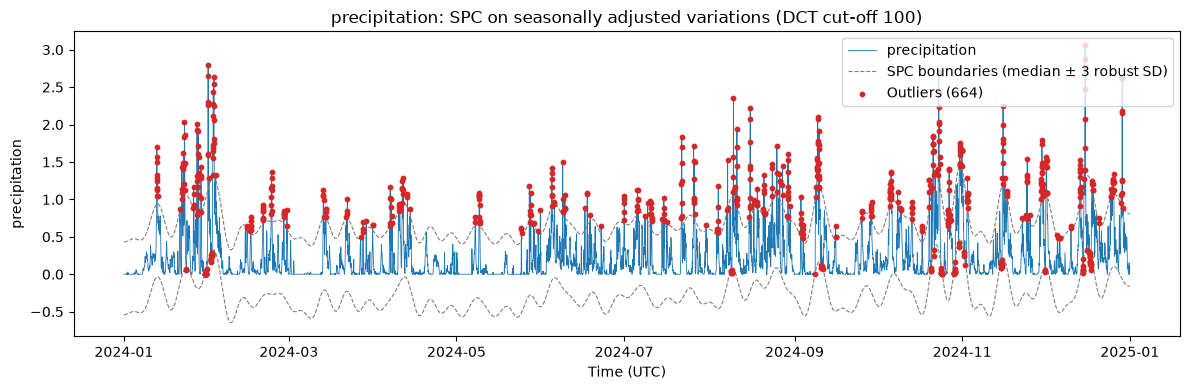

In [9]:
# SPC on the average precipitation with the default settings (cut-off 100, 3 robust standard deviations)
fig, precip_outliers, precip_summary = spc_outliers(weather_no3_mean["precipitation"])
display(precip_summary)
# The five outliers with the largest SATV, i.e. the strongest showers compared with the seasonal level
precip_outliers.sort_values("satv", ascending=False).head()

observations         8784.000
outliers               37.000
outlier share (%)       0.420
above upper limit      15.000
below lower limit      22.000
SATV median            -0.006
SATV robust SD          1.970
dtype: float64

,value,satv
time,,
2024-05-15 00:00:00,7.65,-6.493997
2024-05-15 01:00:00,7.56,-6.601440
2024-05-15 02:00:00,7.36,-6.816429
2024-05-15 03:00:00,7.43,-6.758966
2024-05-15 04:00:00,8.22,-5.979051


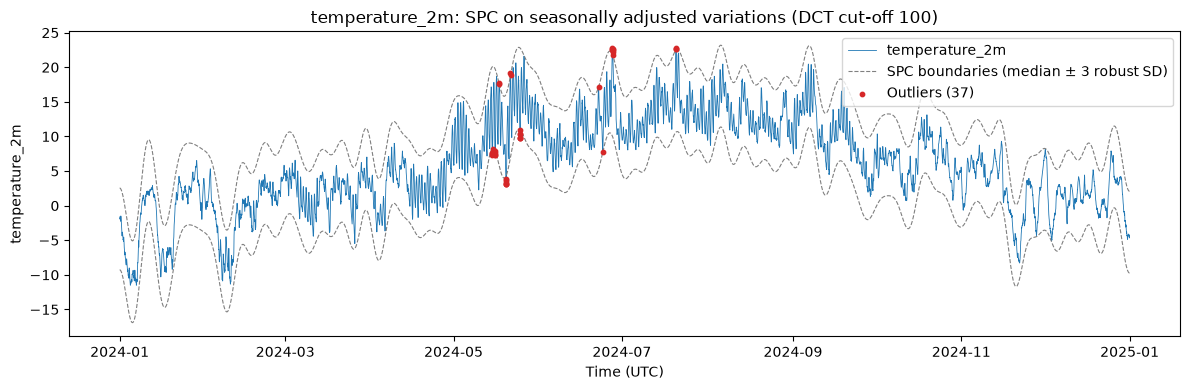

In [10]:
# Test: the same function on the average temperature, the variable used for SATV in last year's task
fig, temp_outliers, temp_summary = spc_outliers(weather_no3_mean["temperature_2m"])
display(temp_summary)
# The first outliers in time
temp_outliers.head()

With the default settings the temperature has few outliers (about 0.4 %), while the precipitation has many (about 7.6 %). SPC assumes symmetric variations around a centre: this holds for the temperature, but precipitation is often zero and occasionally high, so every heavy shower exceeds the upper limit. A larger `n_std` (e.g. 5) gives fewer precipitation outliers.

### Average temperature with anomalies according to the Local Outlier Factor (LOF)
As in the book, LOF is applied to two features: the standardised value and the time position, so that each hour is compared with the hours that are close both in time and in value.

In [11]:
from sklearn.neighbors import LocalOutlierFactor


def lof_anomalies(series, contamination=0.01, n_neighbors=20, days_per_unit=7.0):
    """Local Outlier Factor anomalies in an hourly series.

    Each hour is a point with two features, as in the book: the standardised value and the time position.
    days_per_unit sets how many days of time count as much as one standard deviation of the value,
    so the neighbours of an hour are the hours that are close both in time and in value.
    contamination: expected proportion of anomalies (default 1 %).
    Returns the figure, a table of the anomalies and a summary.
    """
    values = series.to_numpy()
    days = (series.index - series.index[0]) / pd.Timedelta(days=1)
    features = np.column_stack([(values - values.mean()) / values.std(), days / days_per_unit])

    lof = LocalOutlierFactor(n_neighbors=n_neighbors, contamination=contamination)
    is_anomaly = lof.fit_predict(features) == -1          # -1 = anomaly, 1 = normal
    lof_score = -lof.negative_outlier_factor_             # around 1 for normal points, larger for anomalies

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(series.index, values, linewidth=0.6, color="#1f77b4", label=series.name)
    ax.scatter(series.index[is_anomaly], values[is_anomaly], s=12, color="#d62728", zorder=3,
               label=f"LOF anomalies ({is_anomaly.sum()})")
    ax.set_title(f"{series.name}: Local Outlier Factor anomalies (proportion {contamination:.1%})")
    ax.set_xlabel("Time (UTC)")
    ax.set_ylabel(series.name)
    ax.legend(loc="upper right")
    fig.tight_layout()

    anomalies = pd.DataFrame({"value": values[is_anomaly], "lof_score": lof_score[is_anomaly].round(2)},
                             index=series.index[is_anomaly])
    summary = pd.Series({
        "observations": len(values),
        "anomalies": int(is_anomaly.sum()),
        "anomaly share (%)": round(100 * is_anomaly.mean(), 2),
        "mean of anomalies": round(values[is_anomaly].mean(), 2),
        "mean of all values": round(values.mean(), 2),
        "LOF score threshold": round(lof_score[is_anomaly].min(), 2),
    })
    return fig, anomalies, summary

observations           8784.00
anomalies                88.00
anomaly share (%)         1.00
mean of anomalies         3.07
mean of all values        5.97
LOF score threshold       1.60
dtype: float64

,value,lof_score
time,,
2024-11-24 10:00:00,1.15,3.07
2024-11-24 11:00:00,1.70,2.61
2024-01-20 15:00:00,-4.53,2.13
2024-01-20 14:00:00,-4.71,2.11
2024-01-20 16:00:00,-3.85,2.10


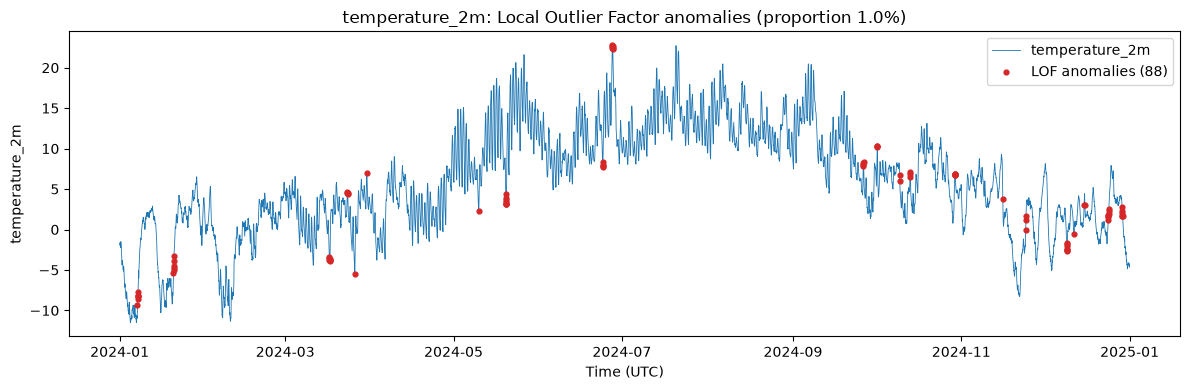

In [12]:
# LOF on the average temperature with the default proportion of anomalies (1 %)
fig, temp_anomalies, temp_lof_summary = lof_anomalies(weather_no3_mean["temperature_2m"])
display(temp_lof_summary)
# The five most anomalous hours (highest LOF score)
temp_anomalies.sort_values("lof_score", ascending=False).head()

observations           8784.00
anomalies                88.00
anomaly share (%)         1.00
mean of anomalies         0.68
mean of all values        0.25
LOF score threshold       1.79
dtype: float64

,value,lof_score
time,,
2024-05-21 17:00:00,0.12,4.42
2024-12-29 05:00:00,2.62,3.64
2024-05-24 17:00:00,0.12,3.38
2024-09-08 12:00:00,0.08,3.28
2024-12-15 17:00:00,3.06,3.12


observations           8784.00
anomalies               440.00
anomaly share (%)         5.01
mean of anomalies         3.59
mean of all values        5.97
LOF score threshold       1.29
dtype: float64

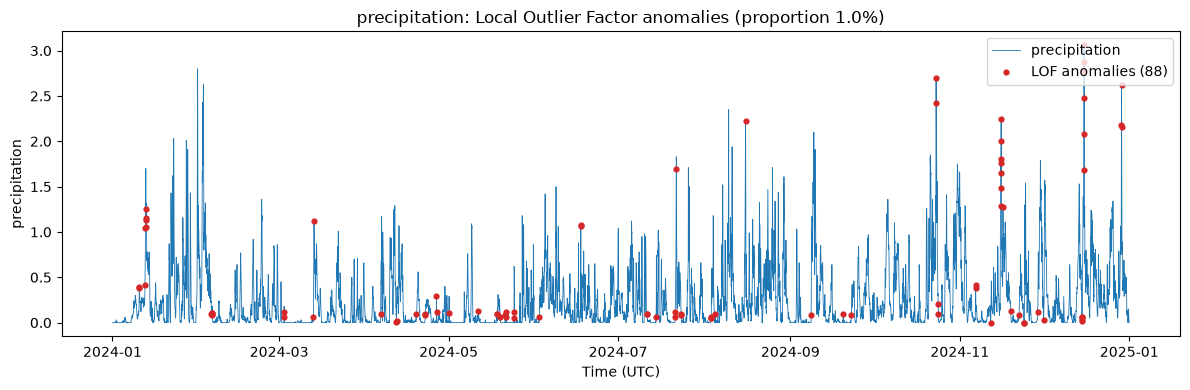

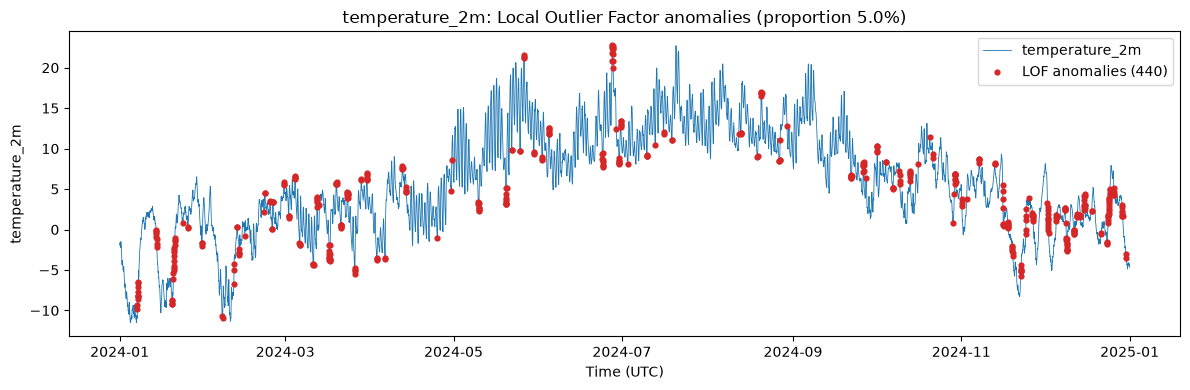

In [13]:
# Test 1: the same function on the precipitation
fig, precip_anomalies, precip_lof_summary = lof_anomalies(weather_no3_mean["precipitation"])
display(precip_lof_summary)
display(precip_anomalies.sort_values("lof_score", ascending=False).head())

# Test 2: a larger proportion of anomalies gives more anomalies with a lower score threshold
_, _, summary_5pct = lof_anomalies(weather_no3_mean["temperature_2m"], contamination=0.05)
summary_5pct

SPC and LOF answer different questions: SPC flags values far from the seasonal level (e.g. heavy showers), while LOF flags hours that are unusual compared with their neighbours in time and value. In the precipitation, LOF therefore also finds light rain during dry periods.

## 4. Seasonal-Trend decomposition (STL) and spectrogram
### Degree of filling from the Magasinstatistikk API

In [14]:
# Weekly reservoir statistics from the NVE API (as in part 2), only the columns needed here
NVE_URL = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"
reservoirs = pd.DataFrame(requests.get(NVE_URL, timeout=60).json())
reservoirs = reservoirs.rename(columns={"dato_Id": "date", "omrType": "area_type", "omrnr": "area_number",
                                        "fyllingsgrad": "filling_rate"})
reservoirs["date"] = pd.to_datetime(reservoirs["date"])
reservoirs = reservoirs.sort_values("date")[["date", "area_type", "area_number", "filling_rate"]]
print(reservoirs.shape, reservoirs["date"].min().date(), "to", reservoirs["date"].max().date())

(14949, 4) 1995-01-08 to 2026-11-01


### STL decomposition with seasonal smoother, trend smoother and robustness as parameters

In [15]:
from statsmodels.tsa.seasonal import STL


def stl_decomposition(data, area_type="NO", area_number=0, period=52, seasonal=13, trend=105, robust=True):
    """Seasonal-Trend decomposition using LOESS of the weekly filling rate of one area.

    period: number of observations per season (52 weeks = one year).
    seasonal, trend: lengths of the seasonal and trend smoothers (odd numbers of weeks).
    robust: down-weights unusual weeks so they do not distort the trend and the season.
    Returns the figure and the STL result.
    """
    series = (data[(data["area_type"] == area_type) & (data["area_number"] == area_number)]
              .set_index("date")["filling_rate"]
              .asfreq("W-SUN"))   # one value per week (every date is a Sunday)
    result = STL(series, period=period, seasonal=seasonal, trend=trend, robust=robust).fit()

    fig = result.plot()   # observed, trend, season and residual in four panels
    fig.set_size_inches(12, 8)
    fig.suptitle(f"STL of the filling rate, {area_type} {area_number} "
                 f"(seasonal={seasonal}, trend={trend}, robust={robust})", y=1.0)
    fig.tight_layout()
    return fig, result

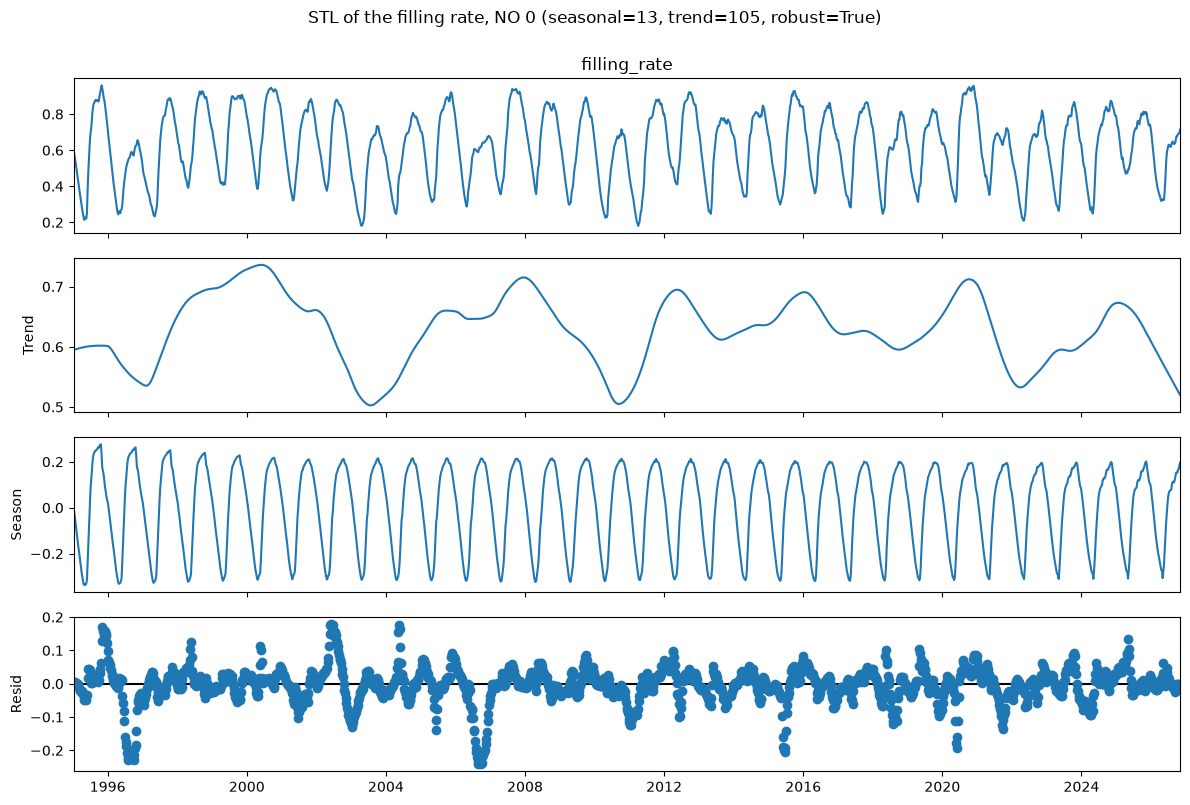

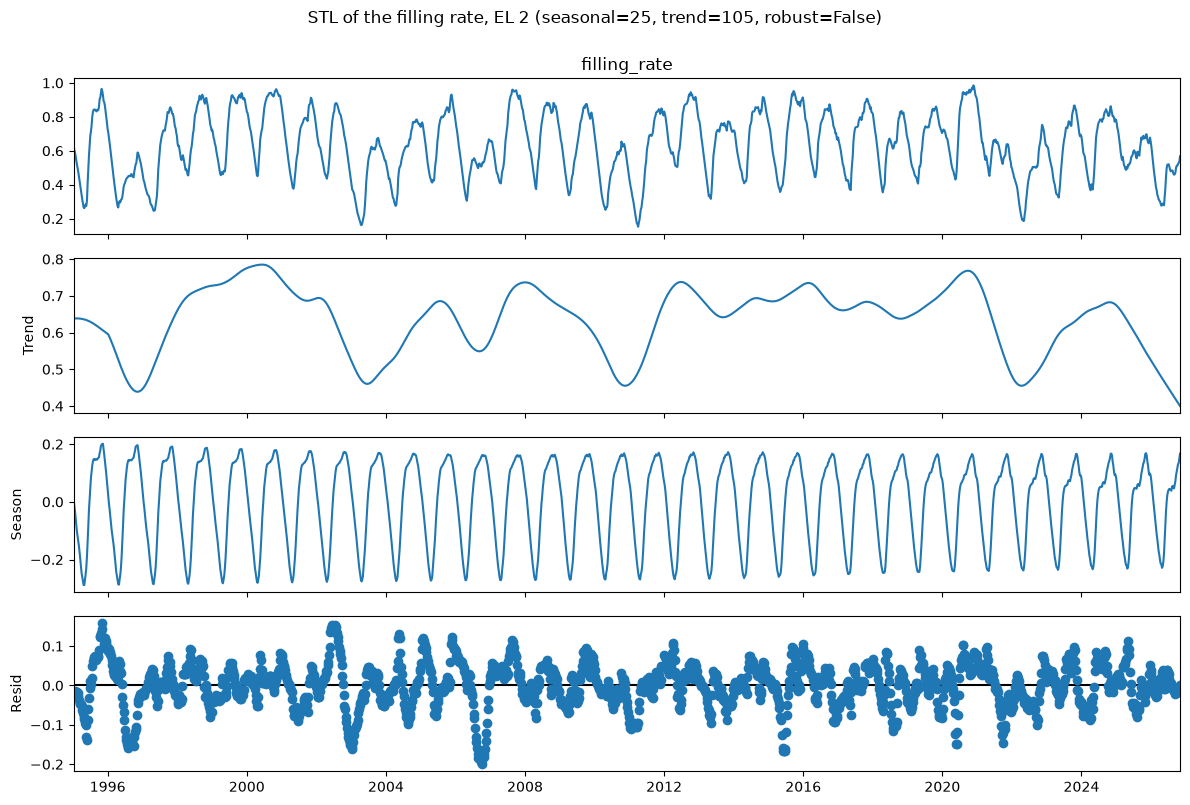

In [16]:
# Default settings: the whole country
fig, stl_result = stl_decomposition(reservoirs)
plt.show()

# Test with other parameters: price area NO2, smoother season, non-robust
fig, _ = stl_decomposition(reservoirs, area_type="EL", area_number=2, seasonal=25, robust=False)
plt.show()

### Spectrogram with window length and window overlap as parameters

In [17]:
from scipy.signal import stft


def spectrogram(data, area_type="NO", area_number=0, window_length=104, window_overlap=78):
    """Spectrogram (short-time Fourier transform) of the weekly filling rate of one area.

    window_length: weeks in each window (104 = two years, so the yearly cycle fits twice in a window).
    window_overlap: weeks shared by consecutive windows (78 = 75 % overlap).
    Returns the figure.
    """
    series = (data[(data["area_type"] == area_type) & (data["area_number"] == area_number)]
              .set_index("date")["filling_rate"])
    values = series.to_numpy() - series.mean()   # remove the mean, otherwise frequency 0 dominates

    # One sample per week: times come out in weeks and frequencies in cycles per week
    freqs, times, Z = stft(values, fs=1, nperseg=window_length, noverlap=window_overlap)
    window_centres = series.index[0] + pd.to_timedelta(times * 7, unit="D")
    freqs = freqs * 365.25 / 7   # cycles per week -> cycles per year

    fig, ax = plt.subplots(figsize=(12, 4))
    mesh = ax.pcolormesh(window_centres, freqs, np.abs(Z), shading="gouraud")
    fig.colorbar(mesh, ax=ax, label="Amplitude")
    ax.set_ylim(0, 6)   # the interesting part: up to 6 cycles per year
    ax.set_xlabel("Time (window centre)")
    ax.set_ylabel("Frequency (cycles per year)")
    ax.set_title(f"Spectrogram of the filling rate, {area_type} {area_number} "
                 f"(window {window_length} weeks, overlap {window_overlap})")
    fig.tight_layout()
    return fig

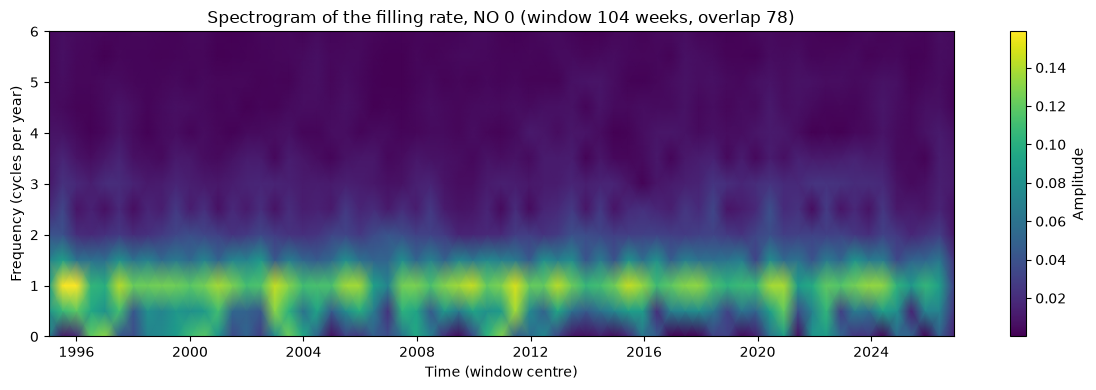

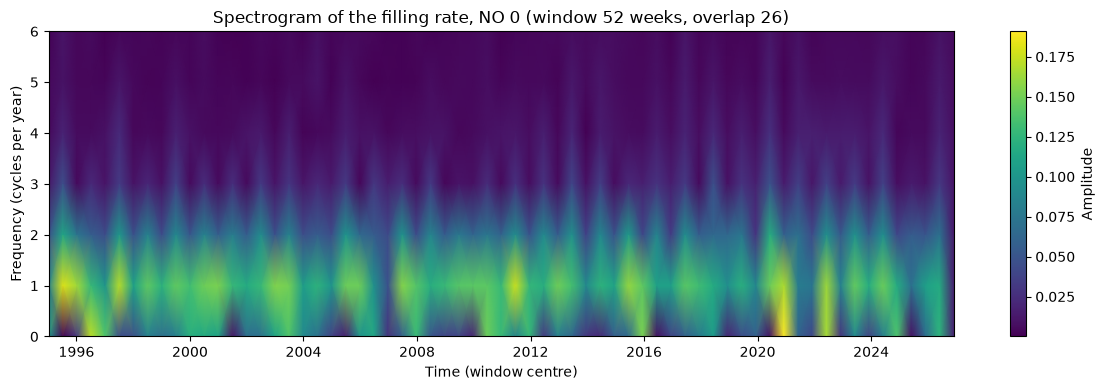

In [18]:
# Default settings: two-year windows with 75 % overlap
spectrogram(reservoirs)
plt.show()

# Test with shorter windows: one year with 50 % overlap (sharper in time, blurrier in frequency)
spectrogram(reservoirs, window_length=52, window_overlap=26)
plt.show()

The STL shows a strong yearly cycle (the reservoirs are emptied in winter and refilled after the snowmelt) and a trend with low years, e.g. around 2003 and 2010. The spectrogram confirms that the energy is concentrated at one cycle per year throughout the period; its strength varies from year to year with how pronounced the seasons are.